# 02 · Prediction examples & validation setup

This notebook **checks** the shared example construction and validation code instead of trusting it:
- `eventflow.data.make_train_examples` / `make_test_examples`: one example = (sequence, cut point);
- `eventflow.validation`: fixed, sequence-grouped folds and one `evaluate` function.

Every model in the project uses exactly these examples and folds, so all results are comparable.

**Decisions (from the EDA, Section 9):**
- Training targets are cut at prefix lengths **90–220**, the range the test set asks about. Earlier events remain history.
- **5 folds grouped by `sequence_id`**. Hyperparameters are tuned on fold 0 only; the final model comparison uses all 5 folds.
- **Primary metric:** log loss over **all test-like cuts** of the held-out systems, every example weighted equally.
- **Check metric:** the **test-mimic** log loss on the single cut per system made like the test set (length − 30).
- Weighting every sequence equally (weight = 1 / its number of cuts) was considered and **rejected**: it over-weights
  short prefixes (Section 3).

Test labels are not loaded here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from eventflow.config import (EVENT_CLASSES, FIGURES_DIR, MAX_PREFIX, MIN_PREFIX, N_CLASSES, N_FOLDS,
                              TEST_MIMIC_OFFSET, TUNING_FOLD)
from eventflow.data import encode_events, load_test, load_train, make_test_examples, make_train_examples
from eventflow.validation import add_folds, assign_folds, evaluate, iter_folds

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.precision", 4)

def savefig(name):
    plt.savefig(FIGURES_DIR / f"val_{name}.png", dpi=150, bbox_inches="tight")

train = load_train()
test = load_test()
examples = add_folds(make_train_examples(train))
test_examples = make_test_examples(test)
print(f"training examples: {len(examples):,} from {examples['sequence_id'].nunique():,} sequences")
print(f"test examples:     {len(test_examples):,}")
display(examples.head())

training examples: 596,953 from 6,500 sequences
test examples:     900


,sequence_id,last_row,prefix_len,target,weight,is_mimic,fold
0,TR00000,89,90,0,0.0333,True,2
1,TR00000,90,91,12,0.0333,False,2
2,TR00000,91,92,12,0.0333,False,2
3,TR00000,92,93,2,0.0333,False,2
4,TR00000,93,94,3,0.0333,False,2


## 1. Correctness checks
Each check should be `True`. They verify the definitions in the code against the raw data.

In [2]:
seq_len = train.groupby("sequence_id").size()
codes = encode_events(train["event_type"])
lr = examples["last_row"].to_numpy()

expected_n = int((np.minimum(MAX_PREFIX, seq_len - 1) - MIN_PREFIX + 1).clip(lower=0).sum())
n_cuts = examples.groupby("sequence_id").size()

checks = {
    "count = sum over sequences of #prefix lengths in [90, min(220, length-1)]": len(examples) == expected_n,
    "every training sequence contributes examples": examples["sequence_id"].nunique() == len(seq_len),
    "(sequence, prefix_len) pairs are unique": not examples.duplicated(["sequence_id", "prefix_len"]).any(),
    "prefix_len within [90, 220]": examples["prefix_len"].between(MIN_PREFIX, MAX_PREFIX).all(),
    "last_row belongs to the example's sequence": (train["sequence_id"].to_numpy()[lr] == examples["sequence_id"].to_numpy()).all(),
    "prefix_len = event_index of last_row + 1": (train["event_index"].to_numpy()[lr] + 1 == examples["prefix_len"].to_numpy()).all(),
    "target row (last_row + 1) is in the same sequence": (train["sequence_id"].to_numpy()[lr + 1] == examples["sequence_id"].to_numpy()).all(),
    "target = event at last_row + 1": (codes[lr + 1] == examples["target"].to_numpy()).all(),
    "weights sum to 1 per sequence": np.allclose(examples.groupby("sequence_id")["weight"].sum(), 1.0),
    "exactly one test-mimic cut per sequence": (examples.groupby("sequence_id")["is_mimic"].sum() == 1).all(),
    "test-mimic cut has prefix_len = length - 30": (examples.loc[examples["is_mimic"], "prefix_len"].to_numpy()
                                                    == seq_len.loc[examples.loc[examples["is_mimic"], "sequence_id"]].to_numpy() - TEST_MIMIC_OFFSET).all(),
    "test: one example per sequence": test_examples["sequence_id"].is_unique and len(test_examples) == test["sequence_id"].nunique(),
    "test: last_row is the last row of its sequence": (test["sequence_id"].to_numpy()[test_examples["last_row"]] == test_examples["sequence_id"].to_numpy()).all()
        and (test.groupby("sequence_id").size().loc[test_examples["sequence_id"]].to_numpy() == test_examples["prefix_len"].to_numpy()).all(),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

print("cuts per sequence:")
display(n_cuts.describe().to_frame("cuts").T)

,passed
"count = sum over sequences of #prefix lengths in [90, min(220, length-1)]",True
every training sequence contributes examples,True
"(sequence, prefix_len) pairs are unique",True
"prefix_len within [90, 220]",True
last_row belongs to the example's sequence,True
prefix_len = event_index of last_row + 1,True
target row (last_row + 1) is in the same sequence,True
target = event at last_row + 1,True
weights sum to 1 per sequence,True
exactly one test-mimic cut per sequence,True


cuts per sequence:


,count,mean,std,min,25%,50%,75%,max
cuts,6500.0,91.8389,33.63,30.0,62.0,95.0,129.0,131.0


> **Notes**
>
> - **No future leakage by construction:** an example stores `last_row`, a pointer into the loaded frame, instead of a copy of its prefix. This keeps 596,953 examples cheap and reduces the no-future rule to one condition: features may only use rows of the same sequence up to `last_row`, and the target is the event at `last_row + 1`.
> - **Checks:** all 13 checks pass, including that every target is the next event of the same sequence and that each sequence has exactly one test-mimic cut.
> - **Uneven contributions:** a sequence of length L gives min(220, L − 1) − 89 cuts, so between 30 (L = 120, prefixes 90–119) and 131 (L ≥ 221). With every example weighted equally, a long system counts up to 4.4× as much as a short one in validation (see Section 3 for why we accept this).

## 2. Folds
Folds are assigned per sequence from a fixed seed. We check that they are balanced, disjoint, reproducible,
and that the class mix is similar in every fold (compared with folds drawn from other seeds).

In [3]:
fold_table = examples.groupby("fold").agg(
    sequences=("sequence_id", "nunique"),
    examples=("target", "size"),
    mean_prefix_len=("prefix_len", "mean"),
)
display(fold_table)

folds_a = assign_folds(train["sequence_id"])
folds_b = assign_folds(train["sequence_id"].sample(frac=1, random_state=1))      # different input order
fold_checks = {
    "every sequence is in exactly one fold": (examples.groupby("sequence_id")["fold"].nunique() == 1).all(),
    "fold sizes differ by at most 1 sequence": fold_table["sequences"].max() - fold_table["sequences"].min() <= 1,
    "assignment is deterministic (same result twice, any input order)": folds_a.equals(folds_b),
    "examples carry the same folds as assign_folds": (examples["fold"].to_numpy() == folds_a.loc[examples["sequence_id"]].to_numpy()).all(),
}
display(pd.Series(fold_checks, name="passed").to_frame())
assert all(fold_checks.values())

,sequences,examples,mean_prefix_len
fold,,,
0,1300,117311,140.7566
1,1300,120820,142.0451
2,1300,119700,141.8064
3,1300,121163,142.2099
4,1300,117959,141.0250


,passed
every sequence is in exactly one fold,True
fold sizes differ by at most 1 sequence,True
"assignment is deterministic (same result twice, any input order)",True
examples carry the same folds as assign_folds,True


In [4]:
# Class mix per fold (all cuts, unweighted like the primary metric), compared with the overall mix
def class_mix(df):
    return pd.Series(np.bincount(df["target"], minlength=N_CLASSES) / len(df), index=EVENT_CLASSES)

mix = pd.DataFrame({f"fold {f}": class_mix(d) for f, d in examples.groupby("fold")})
mix.insert(0, "all", class_mix(examples))
display(mix.round(4))
print(f"largest difference from the overall mix: {mix.drop(columns='all').sub(mix['all'], axis=0).abs().max().max():.4f}")

# Chance level: the same statistic for folds drawn with 20 other seeds
seq_counts = pd.crosstab(examples["sequence_id"], examples["target"]).reindex(columns=range(N_CLASSES), fill_value=0)
overall = seq_counts.sum().to_numpy() / seq_counts.to_numpy().sum()

def max_mix_diff(folds):
    per_fold = seq_counts.groupby(folds.loc[seq_counts.index].to_numpy()).sum()
    return np.abs(per_fold.div(per_fold.sum(axis=1), axis=0).to_numpy() - overall).max()

chance = pd.Series([max_mix_diff(assign_folds(seq_counts.index, seed=s)) for s in range(1, 21)])
print(f"same statistic with 20 other seeds: mean {chance.mean():.4f}, range {chance.min():.4f}-{chance.max():.4f}")

,all,fold 0,fold 1,fold 2,fold 3,fold 4
COMPONENT_REPLACED,0.0455,0.0462,0.0458,0.0452,0.0448,0.0457
CONTROL_ALERT,0.0081,0.0080,0.0081,0.0078,0.0082,0.0081
COOLING_ACTIVATED,0.0460,0.0455,0.0448,0.0466,0.0469,0.0463
COOLING_FAULT,0.0954,0.0942,0.0922,0.1006,0.0942,0.0957
EMERGENCY_STOP,0.0427,0.0417,0.0425,0.0423,0.0436,0.0433
LOAD_DECREASE,0.0202,0.0203,0.0201,0.0204,0.0196,0.0205
LOAD_INCREASE,0.0335,0.0338,0.0344,0.0327,0.0335,0.0331
MAINTENANCE_CHECK,0.1390,0.1395,0.1386,0.1396,0.1387,0.1387
PRESSURE_WARNING,0.0131,0.0132,0.0131,0.0132,0.0132,0.0129
RECOVERY,0.3067,0.3093,0.3119,0.3019,0.3061,0.3044


largest difference from the overall mix: 0.0052
same statistic with 20 other seeds: mean 0.0060, range 0.0033-0.0086


> **Notes**
>
> - **Balanced:** every fold holds exactly 1,300 systems, 117k–121k examples and a mean prefix length of 141–142.
> - **Class mix:** each fold is within 0.0052 of the overall mix. Re-drawing the folds with 20 other seeds gives a largest difference of 0.0060 on average (range 0.0033–0.0086), so our folds are as balanced as chance allows, and no fold is unusual.
> - **Reproducible:** the assignment depends only on the set of sequence IDs and the seed, not on row order (checked by shuffling the input). Every team member and every model gets the same folds, also after changes to loading or sorting.
> - **Decision:** the folds are frozen (seed 2210). Nobody re-splits, and every result is reported on these folds.

## 3. Do the validation cuts look like the test set?
The test prefixes have lengths 90–220, one per system. Our validation examples cover the same range, but with
**several cuts per sequence**. We compare the prefix-length distributions of: all cuts (unweighted), all cuts
weighted per sequence, the test-mimic cuts, and the real test prefixes.

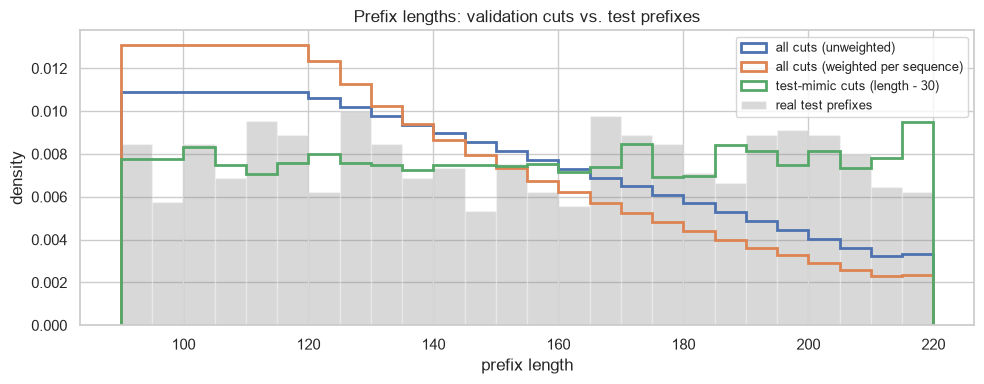

KS test, test-mimic cuts vs. real test prefixes: p = 0.782


In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(MIN_PREFIX, MAX_PREFIX + 2, 5)
ax.hist(examples["prefix_len"], bins=bins, density=True, histtype="step", lw=2, label="all cuts (unweighted)")
ax.hist(examples["prefix_len"], bins=bins, weights=examples["weight"], density=True, histtype="step", lw=2,
        label="all cuts (weighted per sequence)")
ax.hist(examples.loc[examples["is_mimic"], "prefix_len"], bins=bins, density=True, histtype="step", lw=2,
        label="test-mimic cuts (length - 30)")
ax.hist(test_examples["prefix_len"], bins=bins, density=True, alpha=.3, color="grey", label="real test prefixes")
ax.set_xlabel("prefix length"); ax.set_ylabel("density"); ax.legend(fontsize=9)
ax.set_title("Prefix lengths: validation cuts vs. test prefixes")
plt.tight_layout(); savefig("prefix_coverage"); plt.show()

ks = stats.ks_2samp(examples.loc[examples["is_mimic"], "prefix_len"], test_examples["prefix_len"])
print(f"KS test, test-mimic cuts vs. real test prefixes: p = {ks.pvalue:.3f}")

**Does the weighting change the score?** The mismatch above only matters if prediction quality depends on the prefix
length. Quick check on the tuning fold with two simple n-gram predictors (last 1 and last 3 events, add-α smoothing
towards the class prior, α = 1): loss by prefix length, and the score under four weightings. *Length-matched* weights
each cut by 1 / (number of cuts with that prefix length), which makes the prefix lengths uniform like the test set.

In [6]:
codes_all = encode_events(train["event_type"])
tr_f, va_f = examples[examples["fold"] != TUNING_FOLD], examples[examples["fold"] == TUNING_FOLD]

def context_key(last_rows, k):
    key = np.zeros(len(last_rows), np.int64)
    for j in range(k):
        key = key * (N_CLASSES + 1) + codes_all[last_rows - j]
    return key

cuts_per_length = examples.groupby("prefix_len").size()
by_length, by_weighting = {}, {}
for k in [1, 3]:
    k_tr, k_va = context_key(tr_f["last_row"].to_numpy(), k), context_key(va_f["last_row"].to_numpy(), k)
    uniq, inv = np.unique(np.concatenate([k_tr, k_va]), return_inverse=True)
    counts = np.zeros((len(uniq), N_CLASSES))
    np.add.at(counts, (inv[:len(k_tr)], tr_f["target"].to_numpy()), 1)
    prior = np.bincount(tr_f["target"], minlength=N_CLASSES) / len(tr_f)
    probs = (counts + N_CLASSES * prior) / (counts.sum(1, keepdims=True) + N_CLASSES)
    loss = -np.log(probs[inv[len(k_tr):], va_f["target"].to_numpy()])
    name = f"last {k} event{'s' if k > 1 else ''}"
    by_length[name] = pd.Series(loss).groupby(pd.cut(va_f["prefix_len"].to_numpy(), [89, 120, 150, 180, 220])).mean()
    by_weighting[name] = {
        "sequence-weighted": np.average(loss, weights=va_f["weight"]),
        "unweighted (primary)": loss.mean(),
        "length-matched": np.average(loss, weights=1 / va_f["prefix_len"].map(cuts_per_length)),
        "test-mimic (check)": loss[va_f["is_mimic"].to_numpy()].mean(),
    }
display(pd.DataFrame(by_length).rename_axis("prefix length").round(4))
display(pd.DataFrame(by_weighting).round(4))

,last 1 event,last 3 events
prefix length,,
"(89, 120]",1.7749,1.6593
"(120, 150]",1.7626,1.6538
"(150, 180]",1.7791,1.6612
"(180, 220]",1.7613,1.6393


,last 1 event,last 3 events
sequence-weighted,1.7695,1.6556
unweighted (primary),1.7701,1.6549
length-matched,1.7690,1.6523
test-mimic (check),1.7476,1.6430


> **Notes**
>
> - **Coverage:** only the test-mimic cuts match the test prefix lengths (KS p = 0.78), which are spread evenly over 90–220. All cuts over-represent short prefixes: every system has cuts at 90–119, but only long systems reach 200+. Weighting per sequence makes it worse, because short systems put all their weight on short prefixes.
> - **Does it matter?** Not for these predictors: the loss changes by at most 0.02 between length bins, with no clear trend, so the unweighted, sequence-weighted and length-matched scores agree within 0.003.
> - **Test-mimic is lower** by 0.012–0.022. That is about the mimic metric's fold-to-fold noise (std 0.020, Section 4), so it is consistent with chance and not a sign that the test set is easier.
> - **Decision:** the primary metric is unweighted: the simplest, lowest-variance choice, and almost identical to length-matched. Test-mimic is kept as a check. Caveat: if long-context models improve with longer prefixes, the primary will be slightly pessimistic, because it over-represents short prefixes. We re-check loss by prefix length for those models (TASKS.md, Phase 3).

## 4. Smoke test of `evaluate` and fold-to-fold noise
**Not a baseline experiment** (step 3 runs the baselines properly and logs them). We predict the class prior of
the training folds for every example in the validation fold, only to check that `evaluate` works and to see how
much the two metrics move between folds. That variation tells us how large a difference between two models
must be before we believe it.

In [7]:
rows = []
for fold, tr, va in iter_folds(examples):
    prior = np.bincount(tr["target"], minlength=N_CLASSES) / len(tr)
    rows.append({"fold": fold, **evaluate(va, np.tile(prior, (len(va), 1)))})
smoke = pd.DataFrame(rows).set_index("fold")
display(smoke.round(4))

summary = smoke[["logloss", "logloss_mimic"]].agg(["mean", "std"]).T
summary["std error of 5-fold mean"] = summary["std"] / np.sqrt(N_FOLDS)
display(summary.round(4))

,logloss,logloss_mimic,n_examples,n_sequences
fold,,,,
0,2.1634,2.1606,117311,1300
1,2.1569,2.1371,120820,1300
2,2.1677,2.1634,119700,1300
3,2.1649,2.1661,121163,1300
4,2.1664,2.1938,117959,1300


,mean,std,std error of 5-fold mean
logloss,2.1638,0.0042,0.0019
logloss_mimic,2.1642,0.0202,0.0090


> **Notes**
>
> - **Agreement:** for the class prior, both metrics give 2.164 on average (2.1638 vs. 2.1642).
> - **Noise:** across folds, the primary varies by 0.004 (std) and the mimic check by 0.020, about 5× more. The mimic metric uses 1,300 examples per fold instead of ~120,000; independent examples would make it √(120,000 / 1,300) ≈ 10× noisier. It is only 5×, because cuts from the same system are correlated.
> - **Reference score:** the prior scores 2.164 here vs. 2.239 in the EDA, mostly because test-like targets exclude the warm-up phase, whose event mix is different. This is the **ceiling** for every model on this metric: a model that scores worse is broken.
> - **What counts as a real difference:** the 5-fold mean has a standard error of 0.0019, so two models' means must differ by about 0.005 (2 × √2 × 0.0019) before we trust it. Comparing fold by fold on the same folds is more sensitive, because fold difficulty cancels (fold 1 is the easiest for the prior). A model that wins on all 5 folds is convincing (1 in 32 by chance). This noise level was measured for the prior only; we re-check it with the baselines in step 3.
> - **Decision:** report the 5-fold mean ± std of the primary metric, compare models fold by fold, and use the mimic metric only to catch large disagreements.

## 5. How models use this setup

```python
from eventflow.config import TUNING_FOLD
from eventflow.data import load_train, make_train_examples
from eventflow.validation import add_folds, evaluate, iter_folds, split
from eventflow.tracking import log_experiment

train = load_train()
examples = add_folds(make_train_examples(train))

# Tuning: fold 0 only
tr, va = split(examples, TUNING_FOLD)
model.fit(features(train, tr), tr["target"])            # features may only use rows <= last_row of the same sequence
scores = evaluate(va, model.predict_proba(features(train, va)))

# Final comparison: all folds, same folds for every model
for fold, tr, va in iter_folds(examples):
    ...

log_experiment(run_id=..., author=..., model=..., feature_set=..., val_logloss=scores["logloss"], params={...})
```

Anything fitted on data (scalers, clipping thresholds, imputers, vocabularies) is fitted on `tr` only.